## 1. Load (subsampled) + feature prep

In [ ]:
import numpy as np, pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

ROOT = Path.cwd();  ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
PARQUET = ROOT / "Output" / "scenario_ml.parquet"

# 238M rows (567K structural x 420 workload mixes) -> subsample ~1.2M for training.
pf = pq.ParquetFile(PARQUET)
TOTAL = pf.metadata.num_rows
FRAC, SEED = 1_200_000 / TOTAL, 42
parts = []
for batch in pf.iter_batches(batch_size=500_000):
    d = batch.to_pandas()
    parts.append(d.sample(frac=FRAC, random_state=SEED))
df = pd.concat(parts, ignore_index=True)
del parts
print(f"Subsampled {len(df):,} rows from {TOTAL:,} ({FRAC:.2%}).")
print(f"Profiles: {df['profile_id'].nunique()} | mixes: {df['mix_id'].nunique()}")

Subsampled 1,200,225 rows from 238,140,000 (0.50%).
Profiles: 100 | mixes: 420


In [2]:
COLS8 = ['w_name','w_city','w_tax','c_last','balance','c_credit','o_carrier_id','o_ol_cnt']
TARGETS = ['total_time_cost','total_environmental_cost','total_financial_cost']

struct = ['customer_count','order_count'] + [f'sel_{c}' for c in COLS8] + [f'idx_{c}' for c in COLS8]
freq   = [f'freq_q{i}' for i in range(1,21)]
df['model_code'] = df['xml_file'].astype('category').cat.codes
FEATURES = struct + freq + ['data_volume','servers','model_code']
print(f"{len(FEATURES)} features = {len(struct)} structural + {len(freq)} frequency + 3 (vol, srv, model)")
# Trees are scale-invariant, so features stay raw; only the targets are log-transformed.
X = df[FEATURES]
groups = df['profile_id'].values

41 features = 18 structural + 20 frequency + 3 (vol, srv, model)


## 2. Train/test split — by profile



In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, np.zeros(len(X)), groups=groups))
print(f"Train {len(tr):,} rows ({df.iloc[tr]['profile_id'].nunique()} profiles) | "
      f"Test {len(te):,} rows ({df.iloc[te]['profile_id'].nunique()} profiles)")

Train 960,289 rows (80 profiles) | Test 239,936 rows (20 profiles)


## 3. XGBoost vs RandomForest (single split, log targets)

In [5]:
def fit_eval(make_model, name):
    rows = []
    for t in TARGETS:
        y = np.log1p(df[t].values)
        m = make_model()
        m.fit(X.iloc[tr], y[tr])
        pred = m.predict(X.iloc[te])
        rows.append({'model': name, 'target': t,
                     'R2_log': round(r2_score(y[te], pred), 4),
                     'MAE_log': round(mean_absolute_error(y[te], pred), 4)})
    return rows

res = []
res += fit_eval(lambda: XGBRegressor(n_estimators=400, max_depth=8, learning_rate=0.1,
                                     tree_method='hist', n_jobs=-1, random_state=42), 'XGBoost')
res += fit_eval(lambda: RandomForestRegressor(n_estimators=80, n_jobs=-1, random_state=42), 'RandomForest')
comparison = pd.DataFrame(res).pivot(index='target', columns='model', values=['R2_log','MAE_log'])
comparison

R2_log              MAE_log        
model                    RandomForest XGBoost RandomForest XGBoost
target                                                            
total_environmental_cost       0.9283  0.9638       1.0767  0.7754
total_financial_cost           0.9942  0.9966       0.3723  0.3283
total_time_cost                0.9778  0.9864       0.7107  0.5946

## 4. Robust estimate — 5-fold GroupKFold by profile (XGBoost)

In [6]:
gkf = GroupKFold(n_splits=5)
cv_rows = []
for t in TARGETS:
    y = np.log1p(df[t].values)
    r2s = []
    for trf, tef in gkf.split(X, y, groups=groups):
        m = XGBRegressor(n_estimators=400, max_depth=8, learning_rate=0.1,
                         tree_method='hist', n_jobs=-1, random_state=42)
        m.fit(X.iloc[trf], y[trf])
        r2s.append(r2_score(y[tef], m.predict(X.iloc[tef])))
    cv_rows.append({'target': t, 'R2_mean': round(np.mean(r2s), 4), 'R2_std': round(np.std(r2s), 4)})
cv = pd.DataFrame(cv_rows); cv

,target,R2_mean,R2_std
0,total_time_cost,0.9879,0.0022
1,total_environmental_cost,0.9656,0.0106
2,total_financial_cost,0.9961,0.0007


## 5. Feature importance 


Grouped importance (total_time_cost):
  infra+model    0.786
  structural     0.190
  frequency      0.024

Top 12 individual features:
data_volume         0.711603
customer_count      0.122406
model_code          0.060701
freq_q4             0.017028
servers             0.013755
idx_o_carrier_id    0.010259
order_count         0.009858
idx_c_last          0.006647
sel_o_carrier_id    0.006322
idx_w_city          0.006244
sel_o_ol_cnt        0.005203
idx_balance         0.003247


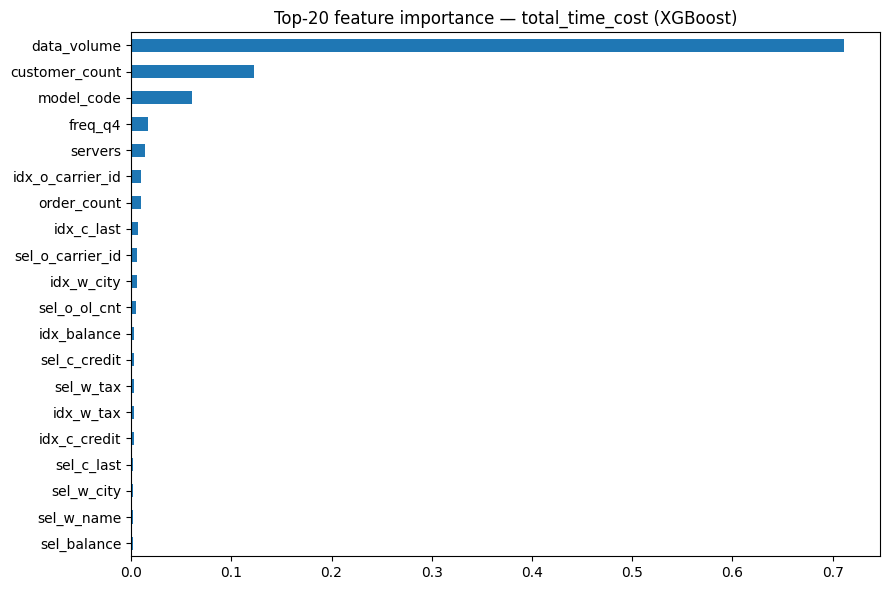

In [7]:
m = XGBRegressor(n_estimators=400, max_depth=8, learning_rate=0.1,
                 tree_method='hist', n_jobs=-1, random_state=42)
m.fit(X.iloc[tr], np.log1p(df['total_time_cost'].values)[tr])
imp = pd.Series(m.feature_importances_, index=FEATURES).sort_values(ascending=False)

# group importance: structural vs frequency vs infra
grp = {'frequency': imp[[f for f in FEATURES if f.startswith('freq_')]].sum(),
       'structural': imp[struct].sum(),
       'infra+model': imp[['data_volume','servers','model_code']].sum()}
print('Grouped importance (total_time_cost):')
for k,v in sorted(grp.items(), key=lambda x:-x[1]): print(f'  {k:14s} {v:.3f}')
print()
print('Top 12 individual features:'); print(imp.head(12).to_string())

fig, ax = plt.subplots(figsize=(9,6))
imp.head(20).iloc[::-1].plot.barh(ax=ax, color='#1f77b4')
ax.set_title('Top-20 feature importance — total_time_cost (XGBoost)'); plt.tight_layout(); plt.show()

## 6. Conclusions

